## Task 1: Introduction to Hugging Face Hub

Hugging Face Hub is an online platform that provides access to pre-trained machine learning and deep learning models, datasets, and applications. It allows developers to discover, share, download, and use models for various AI tasks.

**Key Features:**
- Model Hub: Provides pre-trained models for different AI tasks.
- Dataset Hub: Provides datasets for training and testing models.
- Model Cards: Contains documentation about models, their usage, and limitations.
- Spaces: Allows users to create and share interactive AI applications.

In this task, we explore the Hugging Face Hub using its Python API and retrieve popular image classification models.

In [7]:
# Install Hugging Face Hub
!pip install -q --upgrade huggingface_hub

# Import required library
from huggingface_hub import HfApi

# Initialize Hugging Face API
api = HfApi()

# Retrieve popular image classification models
models = api.list_models(
    pipeline_tag="image-classification",
    sort="downloads",
    limit=5
)

# Display model information
print("Popular Image Classification Models:\n")

for model in models:
    print("Model ID:", model.id)
    print("Downloads:", model.downloads)
    print("-" * 50)

Popular Image Classification Models:

Model ID: google/vit-base-patch16-224
Downloads: 16099072
--------------------------------------------------
Model ID: timm/mobilenetv3_small_100.lamb_in1k
Downloads: 15249612
--------------------------------------------------
Model ID: prithivMLmods/Gender-Classifier-Mini
Downloads: 9776496
--------------------------------------------------
Model ID: timm/tf_efficientnetv2_s.in21k_ft_in1k
Downloads: 3594705
--------------------------------------------------
Model ID: timm/resnet18.a1_in1k
Downloads: 2076605
--------------------------------------------------


## Task 2: Exploring Model Cards

A Model Card is a documentation file available for models on the Hugging Face Hub. It provides important information about a model, including its architecture, intended use, training data, performance, limitations, and license.

Model Cards help users understand the functionality and appropriate usage of pre-trained models.

In this task, we retrieve and explore the details of a pre-trained image classification model using the Hugging Face API.

In [8]:
from huggingface_hub import model_info

# Select a pre-trained image classification model
model_name = "google/vit-base-patch16-224"

# Retrieve model information
info = model_info(model_name)

# Display model details
print("MODEL CARD INFORMATION")
print("-" * 40)

print("Model ID:", info.id)
print("Author:", info.author)
print("Pipeline:", info.pipeline_tag)
print("Library:", info.library_name)
print("Downloads:", info.downloads)
print("Likes:", info.likes)

# Display Model Card URL
print("\nModel Card URL:")
print(f"https://huggingface.co/{model_name}")

MODEL CARD INFORMATION
----------------------------------------
Model ID: google/vit-base-patch16-224
Author: google
Pipeline: image-classification
Library: transformers
Downloads: 16099072
Likes: 1049

Model Card URL:
https://huggingface.co/google/vit-base-patch16-224


## Task 3: Dataset Loading using Hugging Face

The Hugging Face Datasets library provides an easy way to download, access, and process datasets for machine learning and deep learning applications.

The `load_dataset()` function is used to load datasets directly from the Hugging Face Hub.

In this task, we load the IMDb movie review dataset and explore its training and testing samples. The dataset contains movie reviews with sentiment labels (positive and negative).

In [9]:
# Install Hugging Face Datasets
!pip install -q --upgrade datasets

# Import library
from datasets import load_dataset

# Load IMDb dataset
dataset = load_dataset("stanfordnlp/imdb")

# Display dataset information
print("Dataset loaded successfully!\n")

print("Dataset Structure:")
print(dataset)

print("\nTraining Dataset:")
print(dataset["train"])

print("\nTesting Dataset:")
print(dataset["test"])

# Display a sample
sample = dataset["train"][0]

print("\nSample Review:")
print(sample["text"][:500])

print("\nSentiment Label:", sample["label"])
print("0 - Negative")
print("1 - Positive")

Dataset loaded successfully!

Dataset Structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Training Dataset:
Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

Testing Dataset:
Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

Sample Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she w

## Task 4: Implementing 2D Convolution using NumPy

Convolution is a fundamental operation in Convolutional Neural Networks (CNNs). It is used to extract features such as edges, patterns, and textures from images.

A small matrix called a **kernel (filter)** slides over the input matrix and performs element-wise multiplication, followed by summation to generate an output feature map.

In this task, we implement 2D convolution from scratch using NumPy without using built-in convolution functions.

In [10]:
import numpy as np

# Define input matrix
input_matrix = np.array([
    [1, 2, 3, 0, 1],
    [4, 5, 6, 1, 2],
    [7, 8, 9, 2, 3],
    [1, 2, 3, 4, 5],
    [4, 5, 6, 7, 8]
])

# Define 3x3 kernel
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# Define convolution function
def convolution2d(input_matrix, kernel):
    h, w = input_matrix.shape
    kh, kw = kernel.shape

    output = np.zeros((h-kh+1, w-kw+1))

    for i in range(output.shape[0]):
        for j in range(output.shape[1]):
            region = input_matrix[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * kernel)

    return output

# Perform convolution
output = convolution2d(input_matrix, kernel)

print("Input Matrix:")
print(input_matrix)

print("\nKernel:")
print(kernel)

print("\nConvolution Output:")
print(output)

print("\nOutput Shape:", output.shape)

Input Matrix:
[[1 2 3 0 1]
 [4 5 6 1 2]
 [7 8 9 2 3]
 [1 2 3 4 5]
 [4 5 6 7 8]]

Kernel:
[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]

Convolution Output:
[[-6. 12. 12.]
 [-6.  8.  8.]
 [-6.  2.  2.]]

Output Shape: (3, 3)


## Task 5: Implementing Max Pooling using NumPy

Max Pooling is a downsampling operation used in Convolutional Neural Networks (CNNs). It reduces the spatial dimensions of feature maps while retaining the most important features.

In max pooling, a small window moves across the input matrix and selects the maximum value from each region.

In this task, we implement 2D max pooling using NumPy with a configurable pool size and stride.

In [11]:
import numpy as np

# Define input feature map
input_matrix = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 9],
    [3, 4, 5, 6]
])

# Define max pooling function
def max_pooling(input_matrix, pool_size=2, stride=2):

    h, w = input_matrix.shape

    output_height = (h - pool_size) // stride + 1
    output_width = (w - pool_size) // stride + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):

            region = input_matrix[
                i*stride:i*stride+pool_size,
                j*stride:j*stride+pool_size
            ]

            output[i, j] = np.max(region)

    return output

# Perform max pooling
output = max_pooling(input_matrix)

print("Input Matrix:")
print(input_matrix)

print("\nMax Pooling Output:")
print(output)

print("\nOutput Shape:", output.shape)

Input Matrix:
[[1 3 2 4]
 [5 6 1 2]
 [7 2 8 9]
 [3 4 5 6]]

Max Pooling Output:
[[6. 4.]
 [7. 9.]]

Output Shape: (2, 2)


## Task 6: Effect of Different Kernel Sizes

Kernel size determines the area of the input matrix considered during each convolution operation.

Different kernel sizes such as 2×2, 3×3, and 5×5 produce different output feature map dimensions.

In this task, we perform convolution using different kernel sizes and compare their output dimensions.

In [12]:
import numpy as np

# Define input matrix
input_matrix = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 1],
    [2, 3, 4, 5, 6],
    [7, 8, 9, 1, 2],
    [3, 4, 5, 6, 7]
])

# Define convolution function
def convolution2d(input_matrix, kernel):
    h, w = input_matrix.shape
    kh, kw = kernel.shape

    output = np.zeros((h-kh+1, w-kw+1))

    for i in range(output.shape[0]):
        for j in range(output.shape[1]):
            region = input_matrix[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * kernel)

    return output

# Test different kernel sizes
for size in [2, 3, 5]:

    kernel = np.ones((size, size))

    output = convolution2d(input_matrix, kernel)

    print(f"\nKernel Size: {size}x{size}")
    print("Output:")
    print(output)
    print("Output Shape:", output.shape)


Kernel Size: 2x2
Output:
[[16. 20. 24. 19.]
 [18. 22. 26. 21.]
 [20. 24. 19. 14.]
 [22. 26. 21. 16.]]
Output Shape: (4, 4)

Kernel Size: 3x3
Output:
[[36. 45. 45.]
 [54. 54. 45.]
 [45. 45. 45.]]
Output Shape: (3, 3)

Kernel Size: 5x5
Output:
[[118.]]
Output Shape: (1, 1)


## Task 7: Effect of Different Stride Values

Stride determines the number of positions the kernel moves across the input matrix during each convolution operation.

- Stride 1: The kernel moves one position at a time.
- Stride 2: The kernel moves two positions at a time.

Increasing the stride reduces the output feature map dimensions.

In this task, we perform convolution using different stride values and compare the output dimensions.

In [13]:
import numpy as np

# Define input matrix
input_matrix = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 1],
    [2, 3, 4, 5, 6],
    [7, 8, 9, 1, 2],
    [3, 4, 5, 6, 7]
])

# Define 3x3 kernel
kernel = np.ones((3, 3))

# Define convolution function
def convolution2d(input_matrix, kernel, stride=1):

    h, w = input_matrix.shape
    kh, kw = kernel.shape

    output_height = (h-kh)//stride + 1
    output_width = (w-kw)//stride + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):

            region = input_matrix[
                i*stride:i*stride+kh,
                j*stride:j*stride+kw
            ]

            output[i, j] = np.sum(region * kernel)

    return output

# Test different stride values
for stride in [1, 2]:

    output = convolution2d(input_matrix, kernel, stride)

    print(f"\nStride: {stride}")
    print("Output:")
    print(output)
    print("Output Shape:", output.shape)


Stride: 1
Output:
[[36. 45. 45.]
 [54. 54. 45.]
 [45. 45. 45.]]
Output Shape: (3, 3)

Stride: 2
Output:
[[36. 45.]
 [45. 45.]]
Output Shape: (2, 2)


## Task 8: Effect of Padding

Padding is the process of adding extra values, usually zeros, around the boundaries of an input matrix before performing convolution.

There are two common types of padding:

- **Valid Padding:** No padding is added, resulting in smaller output dimensions.
- **Same Padding:** Padding is added to preserve the spatial dimensions of the input when stride is 1.

In this task, we compare convolution outputs with and without zero padding using NumPy.

In [14]:
import numpy as np

# Define input matrix
input_matrix = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 1],
    [2, 3, 4, 5, 6],
    [7, 8, 9, 1, 2],
    [3, 4, 5, 6, 7]
])

# Define 3x3 kernel
kernel = np.ones((3, 3))

# Define convolution function with padding
def convolution2d(input_matrix, kernel, padding=0):

    padded_input = np.pad(
        input_matrix,
        ((padding, padding), (padding, padding)),
        mode='constant'
    )

    h, w = padded_input.shape
    kh, kw = kernel.shape

    output = np.zeros((h-kh+1, w-kw+1))

    for i in range(output.shape[0]):
        for j in range(output.shape[1]):

            region = padded_input[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * kernel)

    return output

# Without padding
output_valid = convolution2d(input_matrix, kernel, padding=0)

# With padding
output_same = convolution2d(input_matrix, kernel, padding=1)

print("Without Padding (Valid):")
print(output_valid)
print("Output Shape:", output_valid.shape)

print("\nWith Padding (Same):")
print(output_same)
print("Output Shape:", output_same.shape)

Without Padding (Valid):
[[36. 45. 45.]
 [54. 54. 45.]
 [45. 45. 45.]]
Output Shape: (3, 3)

With Padding (Same):
[[16. 27. 33. 30. 19.]
 [21. 36. 45. 45. 30.]
 [33. 54. 54. 45. 24.]
 [27. 45. 45. 45. 27.]
 [22. 36. 33. 30. 16.]]
Output Shape: (5, 5)


## Task 9: CNN for CIFAR-10 Image Classification

A Convolutional Neural Network (CNN) is a deep learning model commonly used for image classification and computer vision tasks.

CIFAR-10 is a dataset containing 60,000 color images of size 32×32 pixels belonging to 10 different classes, such as airplanes, cars, birds, cats, and dogs.

In this task, we build a basic CNN using TensorFlow/Keras. The model consists of convolutional layers, max pooling layers, a flattening layer, and fully connected layers. We train and evaluate the model using the CIFAR-10 dataset.

In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training Images Shape:", x_train.shape)
print("Testing Images Shape:", x_test.shape)
print("Dataset loaded successfully!")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1972s 12us/step
Training Images Shape: (50000, 32, 32, 3)
Testing Images Shape: (10000, 32, 32, 3)
Dataset loaded successfully!


In [16]:
# Create CNN model
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 83ms/step - accuracy: 0.4318 - loss: 1.5699 - val_accuracy: 0.4833 - val_loss: 1.4498
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.5645 - loss: 1.2320 - val_accuracy: 0.5829 - val_loss: 1.1829
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 83ms/step - accuracy: 0.6166 - loss: 1.0865 - val_accuracy: 0.6083 - val_loss: 1.1232
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 83ms/step - accuracy: 0.6550 - loss: 0.9929 - val_accuracy: 0.6483 - val_loss: 1.0168
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.6802 - loss: 0.9177 - val_accuracy: 0.6652 - val_loss: 0.9779
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 82ms/step - accuracy: 0.7016 - loss: 0.8590 - val_accuracy: 0.6606 - val_loss: 0.9753
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 82ms/step - accuracy: 0.7238 - loss: 0.8024 - val_accuracy: 0.6795 - val_loss: 0.9325
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 83ms/step - accuracy: 0.7352 - loss: 0.7630 - 

In [18]:
# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6899 - loss: 0.9224

Test Loss: 0.9223992228507996
Test Accuracy: 68.98999810218811 %


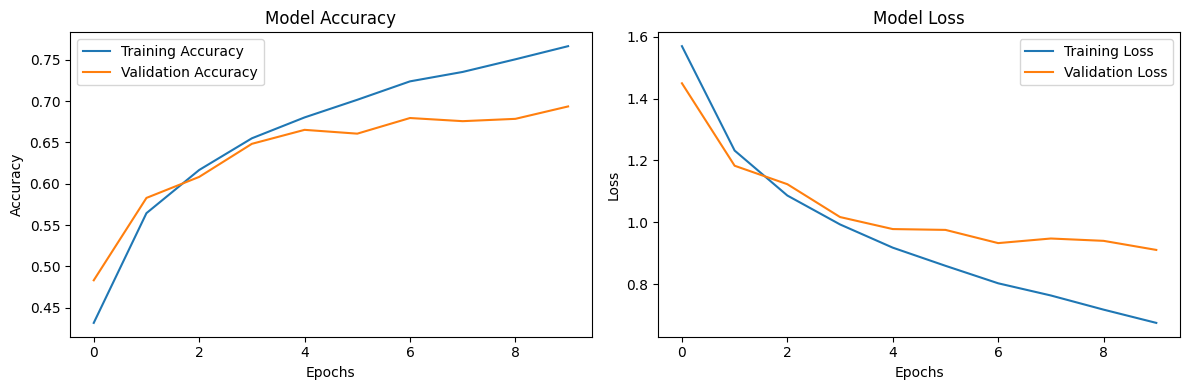

In [19]:
# Plot accuracy and loss
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

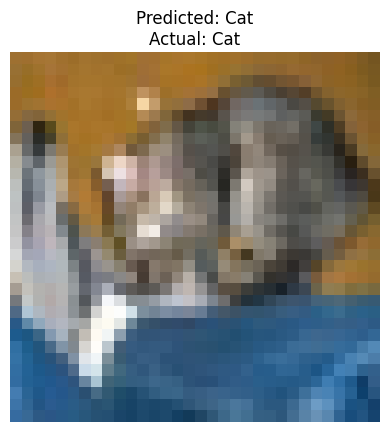

Predicted Class: Cat
Actual Class: Cat


In [22]:
# CIFAR-10 class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Predict a test image
index = 0

prediction = model.predict(x_test[index:index+1], verbose=0)
predicted_class = np.argmax(prediction)
actual_class = y_test[index][0]

# Display image and prediction
plt.imshow(x_test[index])
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis('off')
plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Actual Class:", class_names[actual_class])